In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

In [19]:
data = load_diabetes()
print(data.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [20]:
X = data.data
y = data.target

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=2)

In [22]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

In [23]:
from sklearn.metrics import r2_score,mean_squared_error
print('r2_score ->',r2_score(y_test, y_pred))
print('RMSE ->',np.sqrt(mean_squared_error(y_test, y_pred)))

r2_score -> 0.439933866156897
RMSE -> 55.62784079546915


In [24]:
from sklearn.linear_model import Ridge
rd = Ridge(alpha=0.0001)

In [25]:
rd.fit(X_train, y_train)
y_pred1 = rd.predict(X_test)

In [26]:
print('r2_score ->',r2_score(y_test, y_pred1))
print('RMSE ->',np.sqrt(mean_squared_error(y_test, y_pred1)))

r2_score -> 0.4400429511552678
RMSE -> 55.62242316881657


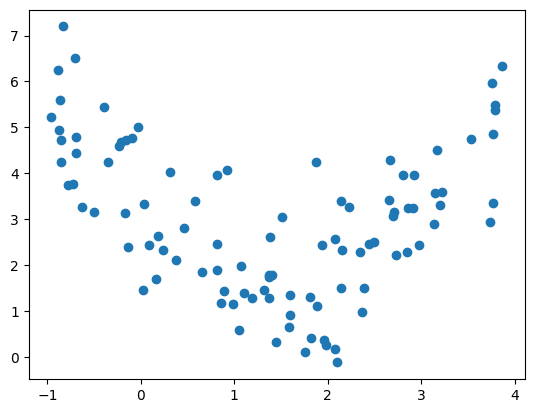

In [27]:
m = 100
x1 = 5* np.random.rand(m,1) - 1
x2 = 0.7 * x1**2 - 2*x1 + 3 + np.random.randn(m,1)

plt.scatter(x1,x2)
plt .show()


/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=3.84821e-19): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/linear_model/_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=6.75903e-18): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


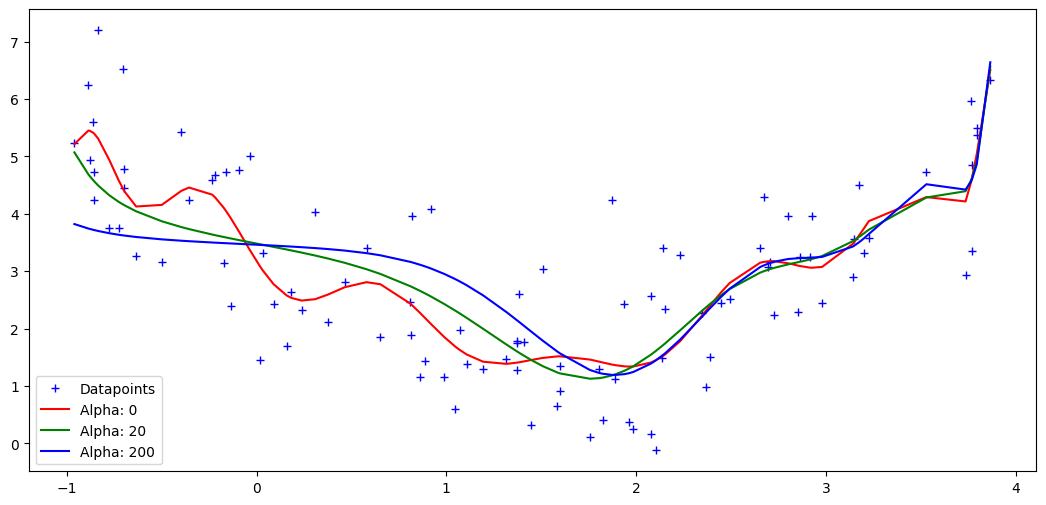

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

def get_preds_ridge(x1, x2, alpha):
    model = Pipeline([
        ('poly_feats',PolynomialFeatures(degree=16)),
        ('ridge', Ridge(alpha=alpha))
    ])
    model.fit(x1,x2)
    return model.predict(x1)

alphas = [0,20,200]
cs = ['r', 'g', 'b']

plt.figure(figsize=(13,6))
plt.plot(x1,x2,'b+',label='Datapoints')

for alpha, c in zip(alphas,cs):
    preds = get_preds_ridge(x1,x2,alpha)

    plt.plot(sorted(x1[:,0]), preds[np.argsort(x1[:,0])],c,label='Alpha: {}'.format(alpha))

plt.legend()
plt.show()